---
title: "Palmer Penguins Clustering"
subtitle: "Unsupervised Methods over Tiny Data using PySpark"
date: 03/12/2024
date-modified: today
date-format: long
engine: jupyter
toc: true
html:
    theme: [default, ../analytics_themes/web_analytics.scss]
categories: ["Spark", "PySpark", "SparkML"]
execute:
  eval: true
---

In [ ]:
import os
import sys
from pyspark.sql import SparkSession

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
spark = SparkSession.builder.config("spark.ui.enabled", "false") \
    .appName("palmerpenguins") \
    .config("spark.driver.host", "localhost") \
    .getOrCreate()

spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

# Load the CSV file into a Spark DataFrame
df = spark.read.option("header", "true").option("inferSchema", "true").option("multiLine","true").option("escape", "\"").option("nullValue", "NA").option("nanValue", "NaN").csv("./data/penguins.csv")

# 3. Register the DataFrame as a temporary SQL table
df.createOrReplaceTempView("palmerpenguins")

# size of the DataFrame

print(f"Size of the DataFrame: {df.count()} rows")
# source .venv/bin/activate
# pip install openpyxl 

df.show(5)

Size of the DataFrame: 344 rows
+-------+---------+--------------+-------------+-----------------+-----------+------+----+
|species|   island|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|   sex|year|
+-------+---------+--------------+-------------+-----------------+-----------+------+----+
| Adelie|Torgersen|          39.1|         18.7|              181|       3750|  male|2007|
| Adelie|Torgersen|          39.5|         17.4|              186|       3800|female|2007|
| Adelie|Torgersen|          40.3|         18.0|              195|       3250|female|2007|
| Adelie|Torgersen|          NULL|         NULL|             NULL|       NULL|  NULL|2007|
| Adelie|Torgersen|          36.7|         19.3|              193|       3450|female|2007|
+-------+---------+--------------+-------------+-----------------+-----------+------+----+
only showing top 5 rows


In [45]:
# import col and when from pyspark 
from pyspark.sql.functions import col, when
# df_clean = df.dropna()
df_clean = spark.sql("""
    SELECT species, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex
    from palmerpenguins
    """
)
df_clean.show(5)
# set Adelie and Chinstrap as small, and Gentoo as large in species_binary
df_clean = df_clean.withColumn("species_binary", when(col("species").isin("Adelie", "Chinstrap"), "small").otherwise("large"))
df_clean.show(5)

+-------+--------------+-------------+-----------------+-----------+------+
|species|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|   sex|
+-------+--------------+-------------+-----------------+-----------+------+
| Adelie|          39.1|         18.7|              181|       3750|  male|
| Adelie|          39.5|         17.4|              186|       3800|female|
| Adelie|          40.3|         18.0|              195|       3250|female|
| Adelie|          NULL|         NULL|             NULL|       NULL|  NULL|
| Adelie|          36.7|         19.3|              193|       3450|female|
+-------+--------------+-------------+-----------------+-----------+------+
only showing top 5 rows
+-------+--------------+-------------+-----------------+-----------+------+--------------+
|species|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|   sex|species_binary|
+-------+--------------+-------------+-----------------+-----------+------+--------------+
| Adelie|          

$$
\begin{align}
\mathbb{P}(y_{Gentoo} = 34.04)
\end{align}
$$

In [46]:
# get the total data points per species
from narwhals import col
from pyspark.sql.functions import col

species_counts = df_clean.groupBy("species").count()
species_counts.show()

bin_species_counts = df_clean.groupBy("species_binary").count()
bin_species_counts.show()

# percentage counts per species
total_count = df_clean.count()

# percentage counts per species binary
bin_species_percentage_counts = bin_species_counts.withColumn("percentage", (col("count") / total_count) * 100)
bin_species_percentage_counts.show()
species_percentage_counts = species_counts.withColumn("percentage", (col("count") / total_count) * 100)
species_percentage_counts.show()

# get the total data points per species per sex
species_sex_counts = df_clean.groupBy("species", "sex").count()
# Show not null values only
# species_sex_counts = species_sex_counts.filter((col("species").isNotNull()) & (col("sex").isNotNull()))
# print(f"Size of the species/sex DataFrame: {species_sex_counts.count()} rows")
species_sex_counts.show()

+---------+-----+
|  species|count|
+---------+-----+
|   Gentoo|  124|
|   Adelie|  152|
|Chinstrap|   68|
+---------+-----+

+--------------+-----+
|species_binary|count|
+--------------+-----+
|         small|  220|
|         large|  124|
+--------------+-----+

+--------------+-----+-----------------+
|species_binary|count|       percentage|
+--------------+-----+-----------------+
|         small|  220|63.95348837209303|
|         large|  124|36.04651162790697|
+--------------+-----+-----------------+

+---------+-----+------------------+
|  species|count|        percentage|
+---------+-----+------------------+
|   Gentoo|  124| 36.04651162790697|
|   Adelie|  152| 44.18604651162791|
|Chinstrap|   68|19.767441860465116|
+---------+-----+------------------+

+---------+------+-----+
|  species|   sex|count|
+---------+------+-----+
|   Gentoo|  NULL|    5|
|   Adelie|  NULL|    6|
|   Gentoo|female|   58|
|Chinstrap|  male|   34|
|Chinstrap|female|   34|
|   Gentoo|  male|   61|
| 

In [47]:
# Size of the cleaned DataFrame
print(f"Size of the cleaned DataFrame: {df_clean.count()} rows")

Size of the cleaned DataFrame: 344 rows


Looking at the proportion of the penguing we can see the data is heavily leaning towards Adelie. Also the male-female ratio seems to be around 1:1.

In [48]:
from pyspark.sql.functions import col, trim, lower

df_clustering = df.select(
    col('species'),
    col("bill_length_mm"),
    col("bill_depth_mm"),
    col("flipper_length_mm"),
    col("body_mass_g")
)
df_clustering = df_clustering.na.drop("any")
print(f"Size of the clustering DataFrame: {df_clustering.count()} rows")
df_clustering.show(5)


Size of the clustering DataFrame: 342 rows
+-------+--------------+-------------+-----------------+-----------+
|species|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|
+-------+--------------+-------------+-----------------+-----------+
| Adelie|          39.1|         18.7|              181|       3750|
| Adelie|          39.5|         17.4|              186|       3800|
| Adelie|          40.3|         18.0|              195|       3250|
| Adelie|          36.7|         19.3|              193|       3450|
| Adelie|          39.3|         20.6|              190|       3650|
+-------+--------------+-------------+-----------------+-----------+
only showing top 5 rows


In [49]:
from pyspark.sql.functions import col
from pyspark.sql.types import StructType, StructField, StringType, DoubleType,DecimalType

column_list = ["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]

for column_name in column_list:
    df_clean = df_clean.withColumn(column_name, col(column_name).cast(DecimalType(8, 2))) # 123.12

df_clean.printSchema()

root
 |-- species: string (nullable = true)
 |-- bill_length_mm: decimal(8,2) (nullable = true)
 |-- bill_depth_mm: decimal(8,2) (nullable = true)
 |-- flipper_length_mm: decimal(8,2) (nullable = true)
 |-- body_mass_g: decimal(8,2) (nullable = true)
 |-- sex: string (nullable = true)
 |-- species_binary: string (nullable = false)



In [50]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

pdf = df.toPandas()

# Clean axis label titles
label_map = {
    "bill_length_mm": "Bill Length (mm)",
    "bill_depth_mm": "Bill Depth (mm)",
    "flipper_length_mm": "Flipper Length (mm)",
    "body_mass_g": "Body Mass (g)"
}

# Create 2x2 subplot grid
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[f"{label} by Species" for label in label_map.values()],
    horizontal_spacing=0.1,
    vertical_spacing=0.15
)

columns = list(label_map.keys())
positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

# Add histograms to each subplot
for col, (row, col_num) in zip(columns, positions):
    for species in pdf["species"].unique():
        subset = pdf[pdf["species"] == species]
        fig.add_trace(
            go.Histogram(
                x=subset[col],
                name=species,
                nbinsx=50,
                opacity=0.5,
                showlegend=True   # <-- legend ON for all traces
            ),
            row=row, col=col_num
        )

    fig.update_xaxes(title_text=f"<b>{label_map[col]}</b>", row=row, col=col_num)
    fig.update_yaxes(title_text="<b>Count</b>", row=row, col=col_num)

# Unified legend settings
fig.update_layout(
    title_text="Penguin Measurements Distribution by Species",
    height=650,
    template="simple_white",
    barmode='overlay',
    legend=dict(
        title="<b>Species</b>",
        tracegroupgap=0
    )
)

fig.show()


c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [51]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

pdf = df.toPandas()
# Clean axis label titles
label_map = {
    "bill_length_mm": "Bill Length (mm)",
    "bill_depth_mm": "Bill Depth (mm)",
    "flipper_length_mm": "Flipper Length (mm)",
    "body_mass_g": "Body Mass (g)"
}

# Create 2x2 subplot grid
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[f"{label} by Species" for label in label_map.values()],
    horizontal_spacing=0.1,
    vertical_spacing=0.15
)
# Column pairs and subplot position
columns = list(label_map.keys())
positions = [(1, 1), (1, 2), (2, 1), (2, 2)]


# Add histograms to each subplot
for i, (col, (row, col_num)) in enumerate(zip(columns, positions)):
    for species in pdf["species"].unique():
        subset = pdf[pdf["species"] == species]
        fig.add_trace(
            go.Histogram(
                x=subset[col],
                name=species,
                nbinsx=20,
                opacity=0.5,
                histnorm='probability density',
                showlegend=True if i == 0 else False  # Only show legend once
            ),
            row=row, col=col_num
        )

    fig.update_xaxes(title_text=f"<b>{label_map[col]}</b>", row=row, col=col_num)
    fig.update_yaxes(title_text="<b>Probability Density</b>", row=row, col=col_num)

fig.update_layout(
    title_text="Penguin Measurements Distribution by Species",
    height=800,
    template="simple_white",
    barmode='overlay'
)

fig.show()

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [52]:
pdf_renamed  = pdf.rename(columns=label_map)

# Feature pairs to plot in 2×2 grid (customized for nice visual contrast)
pairs = [
    ("bill_length_mm", "bill_depth_mm"),
    ("flipper_length_mm", "body_mass_g"),
    ("bill_length_mm", "flipper_length_mm"),
    ("bill_depth_mm", "body_mass_g"),
]

# Prepare the figure layout
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        f"{label_map[x]} vs. {label_map[y]}" for x, y in pairs
    ],
    horizontal_spacing=0.08,
    vertical_spacing=0.12
)

# Plot each scatter
row_col = [(1, 1), (1, 2), (2, 1), (2, 2)]

species_list = pdf["species"].unique()
colors = px.colors.qualitative.Plotly

for idx, ((x, y), (r, c)) in enumerate(zip(pairs, row_col)):
    for i, species in enumerate(species_list):
        species_data = pdf[pdf["species"] == species]
        fig.add_trace(
            go.Scatter(
                x=species_data[x],
                y=species_data[y],
                mode="markers",
                name=species if (r, c) == (1, 1) else None,  # Avoid legend repetition
                marker=dict(color=colors[i], size=6),
                showlegend=(r, c) == (1, 1)
            ),
            row=r, col=c
        )
    # Update axis titles
    fig.update_xaxes(title_text=f"<b>{label_map[x]}</b>", row=r, col=c)
    fig.update_yaxes(title_text=f"<b>{label_map[y]}</b>", row=r, col=c)

# Layout formatting
fig.update_layout(
    height=900,
    template="simple_white",
    title="<b>Pairwise Feature Scatterplots of Penguin Data</b>",
    title_x=0.5
)

fig.show()
fig.write_html("./output/pairwise_scatterplots_penguins.html")
fig.write_image("./output/pairwise_scatterplots_penguins.png", scale=2)
fig.write_image("./output/pairwise_scatterplots_penguins.svg")


In [53]:
from pyspark.sql.functions import col, trim, lower

df_clustering = df.select(
    col('species'),
    col("bill_length_mm"),
    col("bill_depth_mm"),
    col("flipper_length_mm"),
    col("body_mass_g")
)
df_clustering = df_clustering.na.drop("any")
df_clustering.show(5)


+-------+--------------+-------------+-----------------+-----------+
|species|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|
+-------+--------------+-------------+-----------------+-----------+
| Adelie|          39.1|         18.7|              181|       3750|
| Adelie|          39.5|         17.4|              186|       3800|
| Adelie|          40.3|         18.0|              195|       3250|
| Adelie|          36.7|         19.3|              193|       3450|
| Adelie|          39.3|         20.6|              190|       3650|
+-------+--------------+-------------+-----------------+-----------+
only showing top 5 rows


In [54]:
from pyspark.ml.feature import VectorAssembler
from pyspark.sql.types import DoubleType

print("Remaining rows:", df_clustering.count())
for col_name in df_clustering.columns:
    nulls = df_clustering.filter(col(col_name).isNull()).count()
    print(f"{col_name} nulls: {nulls}")


Remaining rows: 342
species nulls: 0
bill_length_mm nulls: 0
bill_depth_mm nulls: 0
flipper_length_mm nulls: 0
body_mass_g nulls: 0


$$
\begin{align}
\mathbb{P}(y|\mathbf{X}) = f(x_{1}, x_{2}, x_{3}, x_{4})\\
\mathbb{P}(\text{Penguin Species}|\text{bill length, bill depth, flipper length,	body mass,	sex}) = p\\
\mathbb{P}(\text{Penguin Species}=Gentoo|\text{bill length, bill depth, flipper length,	body mass,	sex}) = p_1\\
\mathbb{P}(\text{Penguin Species}=Chinstrap|\text{bill length, bill depth, flipper length,	body mass,	sex}) = p_2\\
\mathbb{P}(\text{Penguin Species}=Adelie|\text{bill length, bill depth, flipper length,	body mass,	sex}) = p_3\\
p_1+p_2+p_3 =100\\
\mathbb{P}(\text{Penguin Species}=Gentoo|\text{bill length} = 48.0) =53/124\\
\mathbb{P}(\text{Penguin Species}=Gentoo|\text{bill length} = 48.0, \text{bill depth}= ) =\frac{53}{124}\\
\end{align}
$$

In [55]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.feature import StringIndexer

assembler = VectorAssembler(
    inputCols=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"],
    outputCol="features"
)
data = assembler.transform(df_clustering).select(["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "features", "species"])
all_data = data
all_data.show(5, truncate=False)

data = data.select(["species","features"])

label_indexer = StringIndexer(inputCol="species", outputCol="label")
data = label_indexer.fit(data).transform(data)

# data shape
print(f"Shape of the data DataFrame: {data.count()} rows, {len(data.columns)} columns")
data.show(5, truncate=False)


+--------------+-------------+-----------------+-----------+------------------------+-------+
|bill_length_mm|bill_depth_mm|flipper_length_mm|body_mass_g|features                |species|
+--------------+-------------+-----------------+-----------+------------------------+-------+
|39.1          |18.7         |181              |3750       |[39.1,18.7,181.0,3750.0]|Adelie |
|39.5          |17.4         |186              |3800       |[39.5,17.4,186.0,3800.0]|Adelie |
|40.3          |18.0         |195              |3250       |[40.3,18.0,195.0,3250.0]|Adelie |
|36.7          |19.3         |193              |3450       |[36.7,19.3,193.0,3450.0]|Adelie |
|39.3          |20.6         |190              |3650       |[39.3,20.6,190.0,3650.0]|Adelie |
+--------------+-------------+-----------------+-----------+------------------------+-------+
only showing top 5 rows
Shape of the data DataFrame: 342 rows, 3 columns
+-------+------------------------+-----+
|species|features                |label|

In [56]:
# Convert datasets into a train, test split
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder, CrossValidatorModel

train1_data, test1_data = data.randomSplit([0.8, 0.2], seed=42)
print(f"Shape of the Train data DataFrame: {train1_data.count()} rows, {len(train1_data.columns)} columns")
print(f"Shape of the Test data DataFrame: {test1_data.count()} rows, {len(test1_data.columns)} columns")

train2_data, test2_data, val2_data = data.randomSplit([0.75, 0.2, 0.05], seed=42)
print(f"Shape of the Train data DataFrame: {train2_data.count()} rows, {len(train2_data.columns)} columns")
print(f"Shape of the Test data DataFrame: {test2_data.count()} rows, {len(test2_data.columns)} columns")
print(f"Shape of the Validation data DataFrame: {val2_data.count()} rows, {len(val2_data.columns)} columns")

Shape of the Train data DataFrame: 289 rows, 3 columns
Shape of the Test data DataFrame: 53 rows, 3 columns
Shape of the Train data DataFrame: 274 rows, 3 columns
Shape of the Test data DataFrame: 56 rows, 3 columns
Shape of the Validation data DataFrame: 12 rows, 3 columns


In [ ]:
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql.functions import col

# create the trainer and set its parameters
nb = NaiveBayes(smoothing=1.0, modelType="multinomial")
# One Vs Rest Classifier or Many Vs Many Classifier

# train the model
model1 = nb.fit(train1_data)
model2 = nb.fit(train2_data)

# select example rows to display.
predictions1 = model1.transform(test1_data)
predictions2 = model2.transform(test2_data)
# round predictions df to 2 decimal places
# predictions1 = predictions1.withColumn("prediction", round(col("prediction"), 2))
# predictions2 = predictions2.withColumn("prediction", round(col("prediction"), 2))
predictions1.show(truncate=False)
predictions2.show(truncate=False)

# compute accuracy on the test set
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                              metricName="accuracy")
accuracy1 = evaluator.evaluate(predictions1)
accuracy2 = evaluator.evaluate(predictions2)
# 4 float precision

print("Test accuracy = " + str(round(accuracy1, 2)))
print("Test accuracy = " + str(round(accuracy2, 2)))

+-------+------------------------+-----+-------------------------------------------------------------+--------------------------------------------------------------+----------+
|species|features                |label|rawPrediction                                                |probability                                                   |prediction|
+-------+------------------------+-----+-------------------------------------------------------------+--------------------------------------------------------------+----------+
|Adelie |[33.5,19.0,190.0,3600.0]|0.0  |[-1066.9317529119203,-1073.1485188622282,-1069.6017442326201]|[0.9334902085716384,0.0018629560934382743,0.06464683533492324]|0.0       |
|Adelie |[34.5,18.1,187.0,2900.0]|0.0  |[-1012.2361295200818,-1025.497567017907,-1012.2727058105058] |[0.5091426021728572,8.860746471262524E-7,0.49085651175249556] |0.0       |
|Adelie |[34.6,21.1,198.0,4400.0]|0.0  |[-1159.4053074812987,-1159.1735454845957,-1164.5191820015816]|[0.4411442238

PySparkTypeError: [NOT_EXPECTED_TYPE] Argument `col` should be Column or str, got float.

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


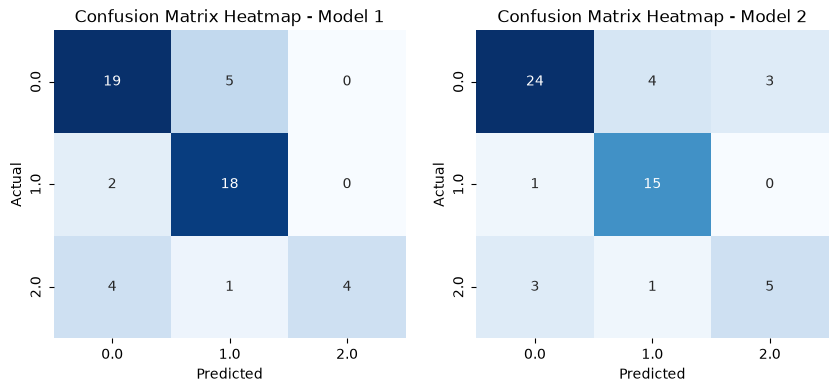

In [ ]:
# Get the confustion table for train1_data and test1_data in to pandas DataFrame

nb_predictions1 = predictions1.toPandas()
nb_predictions2 = predictions2.toPandas()
# nb_predictions1.head()
# nb_predictions2.head()

# Cross tab of label and prediction
confusion_matrix1 = pd.crosstab(nb_predictions1['label'], nb_predictions1['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
confusion_matrix2 = pd.crosstab(nb_predictions2['label'], nb_predictions2['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
# print(confusion_matrix1)
# print(confusion_matrix2)

# display heatmap of confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt


# create a 1 row two column plot for confusion matrices of predictions1 and predictions2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)

cm1 = confusion_matrix1.iloc[:-1, :-1]  # Exclude the 'All' row and column
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Confusion Matrix Heatmap - Model 1')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

cm2 = confusion_matrix2.iloc[:-1, :-1]  # Exclude the 'All' row and column
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Confusion Matrix Heatmap - Model 2')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')
plt.show()

+-------+------------------------+-----+----------------------------------------------------------+------------------------------------------------------------+----------+
|species|features                |label|rawPrediction                                             |probability                                                 |prediction|
+-------+------------------------+-----+----------------------------------------------------------+------------------------------------------------------------+----------+
|Adelie |[33.5,19.0,190.0,3600.0]|0.0  |[0.32522915325037793,-1.398193567561204,-1.2729281120113] |[0.7242581253514878,0.12924697834786134,0.14649489630065074]|0.0       |
|Adelie |[34.5,18.1,187.0,2900.0]|0.0  |[0.24130292617249882,-1.392398013615792,-1.2729281120113] |[0.7066223621186328,0.1379367769489883,0.15544086093237883] |0.0       |
|Adelie |[34.6,21.1,198.0,4400.0]|0.0  |[0.23291030346471064,-1.5120289704737484,-1.2729281120113]|[0.7160826603492046,0.12506784296294116,0

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test accuracy = 0.8302
Test accuracy = 0.8393


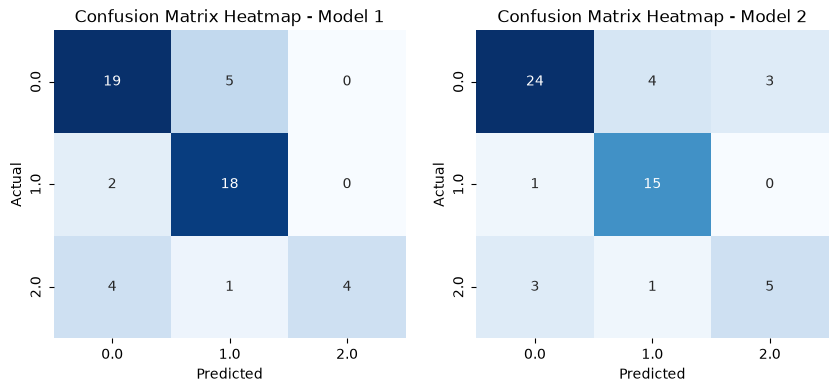

In [ ]:
# Build a logistic regression model using the same train1_data and test1_data datasets
from pyspark.ml.classification import LogisticRegression

model1_lr = LogisticRegression(maxIter=10, regParam=0.3, elasticNetParam=0.8)

# Fit the model
model1 = model1_lr.fit(train1_data)
model2 = model1_lr.fit(train2_data)

lr_predictions1 = model1.transform(test1_data)
lr_predictions2 = model2.transform(test2_data)
lr_predictions1.show(5, truncate=False)
lr_predictions2.show(5, truncate=False)

# confusion matrix for logistic regression model
lr_pred1_df = lr_predictions1.toPandas()
lr_pred2_df = lr_predictions2.toPandas()

evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                              metricName="accuracy")
lr_accuracy1 = evaluator.evaluate(lr_predictions1)
lr_accuracy2 = evaluator.evaluate(lr_predictions2)
# 4 float precision

print("Test accuracy = " + str(round(lr_accuracy1, 4)))
print("Test accuracy = " + str(round(lr_accuracy2, 4)))


confusion_matrix_lr1 = pd.crosstab(lr_pred1_df['label'], lr_pred1_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)

# display heatmap of confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt


# create a 1 row two column plot for confusion matrices of predictions1 and predictions2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)

cm1 = confusion_matrix1.iloc[:-1, :-1]  # Exclude the 'All' row and column
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Confusion Matrix Heatmap - Model 1')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

cm2 = confusion_matrix2.iloc[:-1, :-1]  # Exclude the 'All' row and column
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Confusion Matrix Heatmap - Model 2')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')
plt.show()

# Print the coefficients and intercept for multinomial logistic regression
# print("Coefficients: \n" + str(model1.coefficientMatrix))
# print("Intercept: " + str(model1.interceptVector))

# trainingSummary = model1.summary

# # Obtain the objective per iteration
# objectiveHistory = trainingSummary.objectiveHistory
# print("objectiveHistory:")
# for objective in objectiveHistory:
#     print(objective)

# # for multiclass, we can inspect metrics on a per-label basis
# print("False positive rate by label:")
# for i, rate in enumerate(trainingSummary.falsePositiveRateByLabel):
#     print("label %d: %s" % (i, rate))

# print("True positive rate by label:")
# for i, rate in enumerate(trainingSummary.truePositiveRateByLabel):
#     print("label %d: %s" % (i, rate))

# print("Precision by label:")
# for i, prec in enumerate(trainingSummary.precisionByLabel):
#     print("label %d: %s" % (i, prec))

# print("Recall by label:")
# for i, rec in enumerate(trainingSummary.recallByLabel):
#     print("label %d: %s" % (i, rec))

# print("F-measure by label:")
# for i, f in enumerate(trainingSummary.fMeasureByLabel()):
#     print("label %d: %s" % (i, f))

# accuracy = trainingSummary.accuracy
# falsePositiveRate = trainingSummary.weightedFalsePositiveRate
# truePositiveRate = trainingSummary.weightedTruePositiveRate
# fMeasure = trainingSummary.weightedFMeasure()
# precision = trainingSummary.weightedPrecision
# recall = trainingSummary.weightedRecall
# print("Accuracy: %s\nFPR: %s\nTPR: %s\nF-measure: %s\nPrecision: %s\nRecall: %s"
#       % (accuracy, falsePositiveRate, truePositiveRate, fMeasure, precision, recall))

$$
\begin{align}
P_{Adeile} = 3.1367+ (-0.0839*bill_length_mm) +(-0.1729*bill_depth_mm)+ (0.0171*flipper_length_mm)+(0.001*body_mass_g)\\
P_{Gentoo} = -1.8638+ (-0.0839*bill_length_mm) +(-0.1729*bill_depth_mm)+ (0.0171*flipper_length_mm)+(0.001*body_mass_g)\\
P_{Chinstrap} = -1.2729+ (-0.0839*bill_length_mm) +(-0.1729*bill_depth_mm)+ (0.0171*flipper_length_mm)+(0.001*body_mass_g)
\end{align}
$$

+-------+------------------------+-----+---------------+---------------------------------------------+----------+
|species|features                |label|rawPrediction  |probability                                  |prediction|
+-------+------------------------+-----+---------------+---------------------------------------------+----------+
|Adelie |[33.5,19.0,190.0,3600.0]|0.0  |[113.0,0.0,1.0]|[0.9912280701754386,0.0,0.008771929824561403]|0.0       |
|Adelie |[34.5,18.1,187.0,2900.0]|0.0  |[113.0,0.0,1.0]|[0.9912280701754386,0.0,0.008771929824561403]|0.0       |
|Adelie |[34.6,21.1,198.0,4400.0]|0.0  |[113.0,0.0,1.0]|[0.9912280701754386,0.0,0.008771929824561403]|0.0       |
|Adelie |[35.3,18.9,187.0,3800.0]|0.0  |[113.0,0.0,1.0]|[0.9912280701754386,0.0,0.008771929824561403]|0.0       |
|Adelie |[35.7,18.0,202.0,3550.0]|0.0  |[113.0,0.0,1.0]|[0.9912280701754386,0.0,0.008771929824561403]|0.0       |
+-------+------------------------+-----+---------------+--------------------------------

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test accuracy = 0.9811
Test accuracy = 0.9821


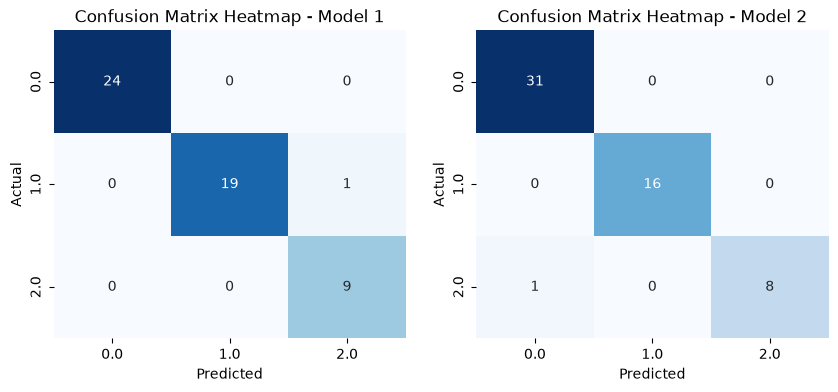

In [ ]:
# Decision Tree Classifier on train1_data and train2_data, test1_data and test2_data datasets
from pyspark.ml.classification import DecisionTreeClassifier

dt_classifier = DecisionTreeClassifier(labelCol="label", featuresCol="features")

dt_model1 = dt_classifier.fit(train1_data)
dt_model2 = dt_classifier.fit(train2_data)

dt_predictions1 = dt_model1.transform(test1_data)
dt_predictions2 = dt_model2.transform(test2_data)
dt_predictions1.show(5, truncate=False)
dt_predictions2.show(5, truncate=False)

# confusion matrix for decision tree model
dt_pred1_df = dt_predictions1.toPandas()
dt_pred2_df = dt_predictions2.toPandas()

evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                              metricName="accuracy")
dt_accuracy1 = evaluator.evaluate(dt_predictions1)
dt_accuracy2 = evaluator.evaluate(dt_predictions2)
# 4 float precision

print("Test accuracy = " + str(round(dt_accuracy1, 4)))
print("Test accuracy = " + str(round(dt_accuracy2, 4)))

confusion_matrix_dt1 = pd.crosstab(dt_pred1_df['label'], dt_pred1_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
confusion_matrix_dt2 = pd.crosstab(dt_pred2_df['label'], dt_pred2_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
# display heatmap of confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt


# create a 1 row two column plot for confusion matrices of predictions1 and predictions2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)

sns.heatmap(confusion_matrix_dt1.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Confusion Matrix Heatmap - Model 1')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

sns.heatmap(confusion_matrix_dt2.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Confusion Matrix Heatmap - Model 2')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.show()



+-------+------------------------+-----+-------------------------------------------+--------------------------------------------+----------+
|species|features                |label|rawPrediction                              |probability                                 |prediction|
+-------+------------------------+-----+-------------------------------------------+--------------------------------------------+----------+
|Adelie |[33.5,19.0,190.0,3600.0]|0.0  |[19.53121719010591,0.0,0.46878280989409205]|[0.9765608595052955,0.0,0.0234391404947046] |0.0       |
|Adelie |[34.5,18.1,187.0,2900.0]|0.0  |[19.64442473727572,0.0,0.35557526272428075]|[0.982221236863786,0.0,0.017778763136214036]|0.0       |
|Adelie |[34.6,21.1,198.0,4400.0]|0.0  |[18.92847704310661,0.0,1.0715229568933906] |[0.9464238521553305,0.0,0.05357614784466953]|0.0       |
|Adelie |[35.3,18.9,187.0,3800.0]|0.0  |[19.82676374881036,0.0,0.1732362511896386] |[0.991338187440518,0.0,0.00866181255948193] |0.0       |
|Adelie |[35.

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test accuracy = 0.9811
Test accuracy = 0.9821


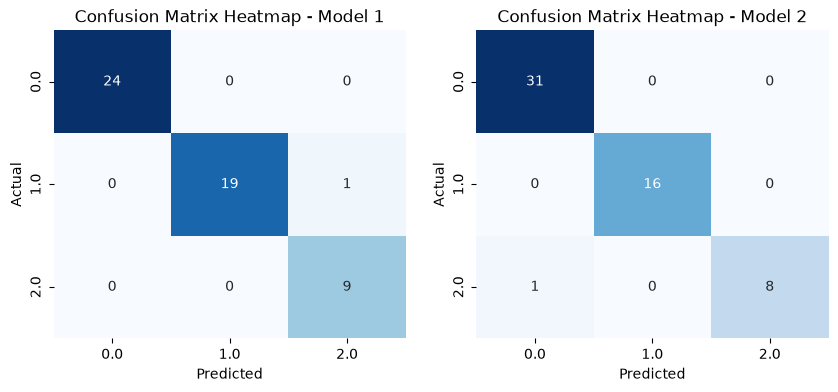

In [ ]:
# Decision Tree Classifier on train1_data and train2_data, test1_data and test2_data datasets
from pyspark.ml.classification import RandomForestClassifier

rf_classifier = RandomForestClassifier(labelCol="label", featuresCol="features")

rf_model1 = rf_classifier.fit(train1_data)
rf_model2 = rf_classifier.fit(train2_data)

rf_predictions1 = rf_model1.transform(test1_data)
rf_predictions2 = rf_model2.transform(test2_data)
rf_predictions1.show(5, truncate=False)
rf_predictions2.show(5, truncate=False)

# confusion matrix for decision tree model
rf_pred1_df = rf_predictions1.toPandas()
rf_pred2_df = rf_predictions2.toPandas()

evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                              metricName="accuracy")
rf_accuracy1 = evaluator.evaluate(rf_predictions1)
rf_accuracy2 = evaluator.evaluate(rf_predictions2)
# 4 float precision

print("Test accuracy = " + str(round(rf_accuracy1, 4)))
print("Test accuracy = " + str(round(rf_accuracy2, 4)))

confusion_matrix_rf1 = pd.crosstab(rf_pred1_df['label'], rf_pred1_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
confusion_matrix_rf2 = pd.crosstab(rf_pred2_df['label'], rf_pred2_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
# display heatmap of confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt


# create a 1 row two column plot for confusion matrices of predictions1 and predictions2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)

sns.heatmap(confusion_matrix_rf1.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Confusion Matrix Heatmap - Model 1')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

sns.heatmap(confusion_matrix_rf2.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Confusion Matrix Heatmap - Model 2')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.show()



+-------+------------------------+-----+------------------------------------------------------------+----------+
|species|features                |label|rawPrediction                                               |prediction|
+-------+------------------------+-----+------------------------------------------------------------+----------+
|Adelie |[33.5,19.0,190.0,3600.0]|0.0  |[1.5435020027249835,-1.5435020027249835,-1.5435020027249833]|0.0       |
|Adelie |[34.5,18.1,187.0,2900.0]|0.0  |[1.5435020027249835,-1.5435020027249835,-1.5435020027249833]|0.0       |
|Adelie |[34.6,21.1,198.0,4400.0]|0.0  |[1.5435020027249835,-1.5435020027249835,-1.5435020027249833]|0.0       |
|Adelie |[35.3,18.9,187.0,3800.0]|0.0  |[1.5435020027249835,-1.5435020027249835,-1.5435020027249833]|0.0       |
|Adelie |[35.7,18.0,202.0,3550.0]|0.0  |[1.5435020027249835,-1.5435020027249835,-1.5435020027249833]|0.0       |
+-------+------------------------+-----+--------------------------------------------------------

c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Program Files\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test accuracy = 0.9623
Test accuracy = 0.9643


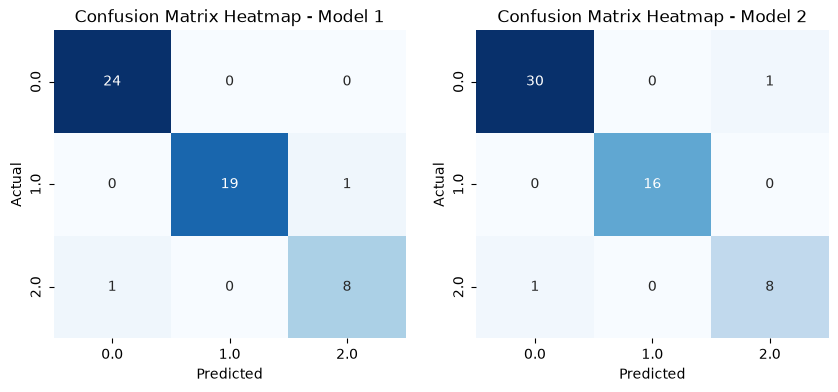

In [ ]:
# Decision Tree Classifier on train1_data and train2_data, test1_data and test2_data datasets
from pyspark.ml.classification import GBTClassifier,OneVsRest
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

gbt_classifier = GBTClassifier(labelCol="label", featuresCol="features")
ovr = OneVsRest(classifier=gbt_classifier)

gbt_model1 = ovr.fit(train1_data)
gbt_model2 = ovr.fit(train2_data)

gbt_predictions1 = gbt_model1.transform(test1_data)
gbt_predictions2 = gbt_model2.transform(test2_data)
gbt_predictions1.show(5, truncate=False)
gbt_predictions2.show(5, truncate=False)

# confusion matrix for decision tree model
gbt_pred1_df = gbt_predictions1.toPandas()
gbt_pred2_df = gbt_predictions2.toPandas()

evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                              metricName="accuracy")
gbt_accuracy1 = evaluator.evaluate(gbt_predictions1)
gbt_accuracy2 = evaluator.evaluate(gbt_predictions2)
# 4 float precision

print("Test accuracy = " + str(round(gbt_accuracy1, 4)))
print("Test accuracy = " + str(round(gbt_accuracy2, 4)))

confusion_matrix_gbt1 = pd.crosstab(gbt_pred1_df['label'], gbt_pred1_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
confusion_matrix_gbt2 = pd.crosstab(gbt_pred2_df['label'], gbt_pred2_df['prediction'], rownames=['Actual'], colnames=['Predicted'], margins=True)
# display heatmap of confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt


# create a 1 row two column plot for confusion matrices of predictions1 and predictions2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)


sns.heatmap(confusion_matrix_gbt1.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Confusion Matrix Heatmap - Model 1')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

sns.heatmap(confusion_matrix_gbt2.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Confusion Matrix Heatmap - Model 2')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.show()



In [ ]:
# Build ROC curve for Naive Bayes, logistic regression, and decision tree model, random forest model, and gradient boosted tree model 3col 2 row grid
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelBinarizer

# get the labels and probabilities from the predictions DataFrame
nb_predictions = gbt_pred2_df[["label", "probability"]]


labels = nb_predictions["label"].values
nb_predictions["probability"] = nb_predictions["probability"].apply(lambda v: np.array(v))
probs = np.vstack(nb_predictions["probability"].values)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(labels)
class_names = lb.classes_
n_classes = len(class_names)


from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle

fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_onehot[:, i], probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(8, 8), dpi=100)
colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=1,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(class_names[i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show() 

KeyError: "['probability'] not in index"

In [ ]:
# k fold cross validation for Naive Bayes model

from ctypes.util import test

from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, OneVsRest
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import HashingTF, Tokenizer
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

lr = LogisticRegression(maxIter=10)
ovr = OneVsRest(classifier=lr)

paramGrid = ParamGridBuilder() \
    .addGrid(lr.regParam, [0.1, 0.01]) \
    .build()

crossval = CrossValidator(estimator=ovr,
                          estimatorParamMaps=paramGrid,
                          evaluator=BinaryClassificationEvaluator(),
                          numFolds=5)  # use 3+ folds in practice

# Run cross-validation, and choose the best set of parameters.
cvModel = crossval.fit(data)

# Make Predictrons from k fold cross validation model
cv_predictions = cvModel.transform(data)
cv_predictions.show(5, truncate=False)

+-------+------------------------+-----+------------------------------------------------------------+----------+
|species|features                |label|rawPrediction                                               |prediction|
+-------+------------------------+-----+------------------------------------------------------------+----------+
|Adelie |[39.1,18.7,181.0,3750.0]|0.0  |[1.8329602335242452,-3.4306515116937426,-1.5173452517268693]|0.0       |
|Adelie |[39.5,17.4,186.0,3800.0]|0.0  |[1.1734729888690438,-2.481528603544918,-1.8357380533355308] |0.0       |
|Adelie |[40.3,18.0,195.0,3250.0]|0.0  |[0.9875931732848304,-2.72559727855192,-1.3398431380256497]  |0.0       |
|Adelie |[36.7,19.3,193.0,3450.0]|0.0  |[2.1518386796169224,-3.4442317940174174,-1.8509662476002635]|0.0       |
|Adelie |[39.3,20.6,190.0,3650.0]|0.0  |[2.0384808736847173,-3.923997577582538,-1.197281482062838]  |0.0       |
+-------+------------------------+-----+--------------------------------------------------------

In [ ]:
# get the cross table of predictions and species
cross_tab = cv_predictions.groupBy("prediction", "species").count().orderBy("prediction", "species")
cross_tab.show()

# Create a pandas datagframe and display confusion matrix
confusion_matrix = cross_tab.toPandas().pivot(index='prediction', columns='species', values='count').fillna(0)
print("Confusion Matrix:") 
print(confusion_matrix.head().to_string(index=False))

# Plot the confusion matrix as a heatmap using Plotly
import plotly.express as px
fig = px.imshow(confusion_matrix, text_auto=True, color_continuous_scale='Blues', labels=dict(x="Species", y="Predicted Cluster", color="Count"), title="Confusion Matrix of K-Means Clustering")
fig.update_layout(template="simple_white", width=600, height=500)



In [ ]:
from pyspark.ml.feature import PCA

pca = PCA(k=2, inputCol="features", outputCol="pcaFeatures")
pca_model = pca.fit(data)
projected = pca_model.transform(data)
pdf_proj = projected.toPandas()

pdf_proj["x"] = pdf_proj["pcaFeatures"].apply(lambda v: float(v[0]))
pdf_proj["y"] = pdf_proj["pcaFeatures"].apply(lambda v: float(v[1]))

fig = px.scatter(pdf_proj, x="x", y="y", color="species", title="PCA Projection Colored by Species")
fig.update_layout(template="simple_white",
                  width=900, 
                  height=700,
                  )
fig.update_xaxes(title_text="<b>Principal Component 1</b>")
fig.update_yaxes(title_text="<b>Principal Component 2</b>")
fig.show()


In [ ]:
from pyspark.ml.clustering import GaussianMixture
from pyspark.sql import functions as F
from pyspark.ml.linalg import Vectors
from pyspark.ml.functions import vector_to_array
from pyspark.mllib.linalg import Vectors as OldVectors


gmm = GaussianMixture(k=3, seed=42, featuresCol="features")
gmm_model = gmm.fit(data)
gmm_pred = gmm_model.transform(data)
gmm_pred.show(5, truncate=False)

# Prob of data point 1 belonging to clusters is [0.99, 0.005, 0.005]
# change the probabilities column to a numeric 0, 1, 2 array of the max probability cluster

gmm_pred = gmm_pred.withColumn(
    "probability_array",
    vector_to_array("probability")
).withColumn(
    "cluster_argmax",
    F.expr("array_position(probability_array, array_max(probability_array)) - 1")
)

gmm_pred.show(5, truncate=False)


+-------+------------------------+-----+---------------------------------------------------------------+----------+
|species|features                |label|probability                                                    |prediction|
+-------+------------------------+-----+---------------------------------------------------------------+----------+
|Adelie |[39.1,18.7,181.0,3750.0]|0.0  |[0.999999998168968,9.155160002553698E-10,9.155160002553698E-10]|0         |
|Adelie |[39.5,17.4,186.0,3800.0]|0.0  |[0.9999999990022692,4.98865369612063E-10,4.988653697916328E-10]|0         |
|Adelie |[40.3,18.0,195.0,3250.0]|0.0  |[0.999999998726516,6.367419675192764E-10,6.367419675228441E-10]|0         |
|Adelie |[36.7,19.3,193.0,3450.0]|0.0  |[0.9999999974983215,1.25083924576935E-9,1.25083924576935E-9]   |0         |
|Adelie |[39.3,20.6,190.0,3650.0]|0.0  |[0.9999999914506115,4.274694276052404E-9,4.274694276052404E-9] |0         |
+-------+------------------------+-----+--------------------------------

In [ ]:
# Project GMM predictions
projected_gmm = pca_model.transform(gmm_pred)
pdf_gmm = projected_gmm.select("pcaFeatures", "prediction").toPandas()
pdf_gmm["x"] = pdf_gmm["pcaFeatures"].apply(lambda v: float(v[0]))
pdf_gmm["y"] = pdf_gmm["pcaFeatures"].apply(lambda v: float(v[1]))


In [ ]:

fig = px.scatter(pdf_gmm, x="x", y="y", color=pdf_gmm["prediction"].astype(str),
                 title="GMM Clustering on PCA-Projected Features")
fig.update_layout(template="simple_white",
                  width=900, 
                  height=700,)
fig.show()


In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.mixture import GaussianMixture

# Step 1: Fit GMM on 2D PCA-projected data
X_proj = pdf_gmm[["x", "y"]].values
gmm_model = GaussianMixture(n_components=len(pdf_gmm["prediction"].unique()), covariance_type='full', random_state=0)
gmm_model.fit(X_proj)

# Step 2: Create a mesh grid over x and y
x = np.linspace(X_proj[:, 0].min() - 1, X_proj[:, 0].max() + 1, 300)
y = np.linspace(X_proj[:, 1].min() - 1, X_proj[:, 1].max() + 1, 300)
xx, yy = np.meshgrid(x, y)
grid = np.c_[xx.ravel(), yy.ravel()]

# Step 3: Predict soft probabilities (posterior) over the mesh
probs = gmm_model.predict_proba(grid)
cluster_map = np.argmax(probs, axis=1).reshape(xx.shape)

# Step 4: Plot prediction area + data points
fig = go.Figure()

# Add contour for soft cluster regions
fig.add_trace(go.Contour(
    x=x, y=y, z=cluster_map,
    showscale=False,
    colorscale="Viridis",
    opacity=0.3,
    contours=dict(
        coloring="heatmap",
        showlines=False
    )
))

# Add data points
for label in sorted(pdf_gmm["prediction"].unique()):
    cluster_data = pdf_gmm[pdf_gmm["prediction"] == label]
    fig.add_trace(go.Scatter(
        x=cluster_data["x"], y=cluster_data["y"],
        mode="markers",
        name=f"Cluster {label}",
        marker=dict(size=5),
        hoverinfo="text",
        text=[f"Cluster: {label}" for _ in range(len(cluster_data))]
    ))

# Update layout
fig.update_layout(
    title="GMM Predicted Clusters with Region Overlay (PCA Projection)",
    xaxis_title="PCA 1",
    yaxis_title="PCA 2",
    template="simple_white",
    height=600,
    width=800
)

fig.show()


In [ ]:
import pandas as pd

# Palmer Penguins: Adelie = 0, Chinstrap = 1
penguins = pd.read_csv("penguins.csv") 
df = penguins[penguins['species'].isin(['Adelie', 'Chinstrap'])].copy()
df['label'] = (df['species'] == 'Chinstrap').astype(int)
df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g'], inplace=True)
X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].values
y = df['label'].values

df.head().style.hide(axis="index")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import numpy as np


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)

ll = -log_loss(y_train, model.predict_proba(X_train), normalize=False)
n = X_train.shape[0]
k = X_train.shape[1] + 1
aic = -2 * ll + 2 * k
bic = -2 * ll + k * np.log(n)

# 4 point decimal precision
print("Log-Likelihood:", f"{ll:.4f}")
print("AIC:", f"{aic:.4f}")
print("BIC:", f"{bic:.4f}")

Log-Likelihood: -4.3802
AIC: 18.7604
BIC: 34.5844


In [ ]:
# # Regression curve
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib import cm
# from mpl_toolkits.mplot3d import Axes3D
# import celluloid
# from celluloid import Camera
# from scipy.special import expit
# from matplotlib import gridspec

# def pred_curve(xs,w0,b0):  # predict y-values for regression curve
#     z=xs.T@w0.T  + b0   
#     p=expit(z)  
#     return p

# # Create data for surface plot: 
# def CrossEntropy_cost(x,y,w0,b0):  # returns costs for every pair of w and b. 
#         p=expit(x @ w0.T + b0)
#         return - np.mean(y*np.log(p) + (1-y)*np.log(1-p))

# ws = np.linspace(-0.005, 0.075, 40) # set range of values for w ... 
# bs = np.linspace(-1.75, 0.75, 40)  # ... and b for surface plot
# M, B = np.meshgrid(ws, bs) # create meshgrid for surface plot
# zs = np.array([CrossEntropy_cost(X_train,y_train,       # determine costs for each pair of w and b 
#                        np.array([[wp]]), np.array([[bp]]))  # CrossEntropy_cost() only accepts wp and bp as matrices. 
#                for wp, bp in zip(np.ravel(M), np.ravel(B))])
# Z = zs.reshape(M.shape) # get z-values for surface plot in shape of M.

# # Define which epochs to plot: 
# a1=np.arange(0,20,1).tolist() 
# a2=np.arange(20,100,20).tolist()
# a3=np.arange(100,500,200).tolist()
# a4=np.arange(500,40000,4000).tolist()
# a5=np.arange(40000,600000,20000).tolist()
# points_ = a1+a2+a3+a4+a5

# # Create first animation (regression curve & surface plot):
# fig = plt.figure(figsize=(10,10)) # create figure
# gs = gridspec.GridSpec(1, 2, height_ratios=[1.7, 1]) # set height ratios of subplots

# label_font_size = 28 # size of label fonts
# tick_label_size= 18 # size of tick labels

# # Customize subplots: 
# ax0=fig.add_subplot(gs[0]) # add first subplot to figure
# ax0.set_title("Logistic regression curve", fontsize=22) #set title
# ax0.tick_params(axis='both', which='major', labelsize=tick_label_size) # set tick label size
# ax0.set_xlabel("x", fontsize=label_font_size, labelpad=5) # set axis labels
# ax0.set_ylabel("y", fontsize=label_font_size, labelpad=5)
# ax0.tick_params(axis='both', which='major',
#                 labelsize=tick_label_size) 
# ax0.set_ylim([-0.05, 1.2]) # set range for y-values in the plot
# ax0.set_yticks([0,0.2,0.4,0.6,0.8, 1]) # set y-axis ticks
# ax0.set_yticklabels(["0","0.2","0.4","0.6","0.8", "1.0"], # label y-ticks
#                     fontsize=tick_label_size)
# ax1=fig.add_subplot(gs[1], projection="3d") # add second subplot 
# ax1.view_init(elev=25, azim=-70) # set view
# ax1.set_xlabel("w", fontsize=label_font_size, labelpad=16) 
# ax1.set_ylabel("b", fontsize=label_font_size, labelpad=18)
# ax1.set_zlabel("costs", fontsize=label_font_size, labelpad=13)  
# ax1.tick_params(axis='both', which='major', labelsize=tick_label_size) 
# ax1.set_xticks([0, 0.02,0.04,0.06]) 
# ax1.set_xticklabels(["0", "0.02","0.04","0.06"], fontsize=tick_label_size)
# ax1.set_yticks([-1.5,-1, -0.5,0,0.5]) 
# ax1.set_yticklabels(["-1.5","-1", "-0.5","0","0.5"], fontsize=tick_label_size)
# ax1.set_zticks([0.4,0.6, 0.8,1.0]) 
# ax1.set_zticklabels(["0.4","0.6", "0.8","1.0"], fontsize=tick_label_size)
# ax1.tick_params(axis='z', pad=7, which='major', labelsize=tick_label_size) 
# plt.tight_layout() # adjusts subplots to figure area

# camera = Camera(fig)  # create camera 
# for i in points_:
    
#     # Plot logistic regression curve: 
#     ys = pred_curve(xs,np.array([w.flatten()[i]]),b.flatten()[i]) #calculate y-values for reg. curve
#     leg=ax0.plot(xs.flatten(),ys.flatten(),
#                  color='r', label=str(i))
    
#     # Scatter plot of training data:
#     ax0.scatter(X_train, y_train, color='b',marker='x', s=92) # plot training data points
#     ax0.legend(leg,[f'costs: {np.round(c.flatten()[i],3)}'], # customize legend
#                loc='upper left', fontsize=18)
    
#     # Plot connecting lines (between predicted y-values and training data points):
#     cl_=cl[i]
#     for j in range(len(y_train)):    
#         x,y = [X_train[j],X_train[j]],[float(y_train[j]),cl_[j]]
#         ax0.scatter(x,y, color='black',s=0.5)
#         ax0.plot(x,y, color='black', linewidth=1.5, 
#                  linestyle='dashed', alpha=0.4)
        
#     # Surface plot of costs:
#     ax1.plot_surface(M, B, Z, rstride=1, cstride=1, 
#                      alpha=0.80,cmap=cm.coolwarm) 
    
#     # Plot trajectory of gradient descent:
#     ax1.plot(w.flatten()[0:i],b.flatten()[0:i], 
#              c.flatten()[0:i], linestyle="dashed",
#              linewidth=2.5, color="black")
#     ax1.scatter(w.flatten()[i],b.flatten()[i],   
#                 c.flatten()[i], marker="o",s=70*2, color="black")
    
#     # Customize legend: 
#     ax1.legend(leg,[f'epochs: {i}'], 
#                loc='upper left', fontsize=18)
    
#     camera.snap() # take snapshot after each frame/iteration
    
# # Create animation: 
# animation = camera.animate(interval = 100, # set delay between frames in milliseconds.
#                           repeat = False, repeat_delay = 0) 
# # Save animation: 
# animation.save('LogReg_1.gif', writer = 'imagemagick') 

# #print("Final weights: "+ str(w.flatten()[i]))    # 0.03579113198262307
# #print("Final bias: "+ str(b[i]))                 # [-1.11258967]
# #print("Final costs: " + str(c[i]))               # [0.40058369]


In [ ]:
#| eval: false
# import seaborn as sns
# from sklearn.tree import DecisionTreeClassifier
# from sklearn import preprocessing
# import dtreeviz

# # Load and clean dataset
# df = sns.load_dataset("penguins").dropna()

# # Encode target
# label_encoder = preprocessing.LabelEncoder()
# df['species_encoded'] = label_encoder.fit_transform(df['species'])

# # Features and target
# X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
# y = df['species_encoded']

# # Train model
# clf = DecisionTreeClassifier(max_depth=3)
# clf.fit(X, y)

# # dtreeviz 2.x+ API
# viz_model = dtreeviz.model(clf,
#                            X_train=X.values,  # Ensure these are numpy arrays
#                            y_train=y.values,
#                            feature_names=X.columns.tolist(),
#                            target_name='species',
#                            class_names=label_encoder.classes_.tolist()  
#                            )

# # Render visualization
# viz = viz_model.view()
# viz             # Interactive viewer
# viz.save("penguins_tree.svg")  # Save as SVG


In [ ]:
# get the prior probabilities for penguins
prior_probs = pdf['species'].value_counts(normalize=False)
prior_probs

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [ ]:
# prior prob for bill length given species
pdf.groupby('species')['bill_length_mm'].value_counts(normalize=False)
# table for conditional probabilities
cond_probs = pdf.groupby('species')['bill_length_mm'].value_counts(normalize=True)
cond_probs

species  bill_length_mm
Adelie   41.1              0.046358
         37.8              0.033113
         39.6              0.033113
         36.0              0.026490
         38.1              0.026490
                             ...   
Gentoo   53.4              0.008130
         54.3              0.008130
         55.1              0.008130
         55.9              0.008130
         59.6              0.008130
Name: proportion, Length: 208, dtype: float64